# Multi-Head Attention

## Big Picture
**Attention** (each item in a sequence looks at all other items and takes a weighted average of them) is the core operation of a Transformer. Multi-head attention runs that operation several times in parallel, each with its own learned view of the data, and then merges the results. This sits under **Pillar 1 (linear algebra)** in the earlier map, because it is only matrix products plus a softmax.

## Summary
* **One head** (one independent attention calculation) can learn only one weighting pattern per layer.
* **Several heads** let the model track different relationships at once, because each head works in its own smaller subspace.
* **Paper's motivation:** A single head averages everything together, which blurs different kinds of information *(Vaswani et al., 2017)*.
* **Compute efficiency:** Total compute stays close to single-head attention, because each head uses a smaller dimension ($d_k = d_{\text{model}} / h$).
* **Pruning:** Not all heads are equally useful, and many can be pruned with little loss.

## The Core Formula

$$\text{head}_i = \text{Attention}(X \cdot W_i^Q, X \cdot W_i^K, X \cdot W_i^V)$$

$$\text{MultiHead} = \text{Concat}(\text{head}_1, \dots, \text{head}_h) \cdot W^O$$

$$\text{Attention}(Q, K, V) = \text{softmax}\left(\frac{Q \cdot K^T}{\sqrt{d_k}}\right) \cdot V$$

* **$Q, K, V$ (Query, Key, Value):** Three learned projections of the same input. Think of:
  * **$Q$:** "what I'm looking for"
  * **$K$:** "what I contain"
  * **$V$:** "what I pass on"
* **$W$ matrices:** Learned weight matrices that training adjusts.
* **Scaling ($\div \sqrt{d_k}$):** Keeps dot products from growing too large, which would push the softmax into regions with tiny gradients.

## Step-by-Step Shapes (Base Transformer)
The base model in the paper uses $d_{\text{model}} = 512$ and $h = 8$, so each head has $d_k = 64$.

1. **Input ($X$):** Shape $n \times 512$ ($n$ = number of tokens or time steps).
2. **Projections:** For each of the 8 heads, project to $Q_i, K_i, V_i$, each of shape $n \times 64$.
3. **Head Attention:** Each head computes its own $n \times n$ attention weights, then outputs $n \times 64$.
4. **Concatenation:** Concatenate the 8 outputs into shape $n \times 512$.
5. **Output Projection:** Multiply by $W^O$ ($512 \times 512$) to mix the heads.

> **Parameter count per layer:** $4 \times 512^2 = 1,048,576$ weights, excluding biases ($Q, K, V$ and output projections). This is the same whether you use 1 head or 8, because the heads split the 512 dimensions rather than add to them.


---
---

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model=512, h=8):
        super().__init__()
        assert d_model % h == 0
        self.h, self.d_k = h, d_model // h
        self.qkv = nn.Linear(d_model, 3 * d_model)
        self.out = nn.Linear(d_model, d_model)

    def forward(self, x):                       # x: (B, n, d_model)
        B, n, _ = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)
        q, k, v = [t.view(B, n, self.h, self.d_k).transpose(1, 2)
                   for t in (q, k, v)]          # (B, h, n, d_k)
        scores = q @ k.transpose(-2, -1) / self.d_k ** 0.5   # (B, h, n, n)
        w = F.softmax(scores, dim=-1)
        z = (w @ v).transpose(1, 2).reshape(B, n, -1)        # concat heads
        return self.out(z)

x = torch.randn(2, 375, 512)                    # 2 samples, 375 steps
print(MultiHeadAttention()(x).shape)            # torch.Size([2, 375, 512])

torch.Size([2, 375, 512])


---
---

# Multi-Head Attention: Step-by-Step Cookbook

## Big Picture
The toy example uses **3 tokens**, **2 heads**, and $d_{\text{model}} = 4$, so each head works with $d_k = 2$. This lets every query and key be drawn as an arrow on a flat page. Every number in the picture was computed by the Python file, and the final row of the output was hand-checked.

## Summary
* The input has **3 tokens with 4 features each**, and the output has the exact same shape.
* Each head makes its own **$Q, K, V$** (query, key, value vectors) from the same $X$.
* The **dot product** (multiply matching numbers, then add) is large when two arrows point the same way.
* **Softmax** (turns scores into positive weights that sum to 1) decides how much each token is copied.
* The weights are hand-picked so the two heads differ: for token $t_2$, **head 1** gives the most weight to itself ($0.768$) and **head 2** gives the most to $t_1$ ($0.768$). In real training, these weights are learned.
* **Total weights:** $3 \times (4 \times 2) \text{ per head} \times 2 \text{ heads} = 48$, plus $W_O$ at $16$, totaling **$64 = 4 \times d_{\text{model}}^2$** as in the earlier formula.

## The Recipe (7 Steps)

| Step | Operation | Shape |
| :--- | :--- | :--- |
| **0** | Input $X$ | $3 \times 4$ |
| **1** | $Q = X \cdot W_Q, \; K = X \cdot W_K, \; V = X \cdot W_V$ (per head) | $3 \times 2$ each |
| **2** | Scores $S = Q \cdot K^T$ | $3 \times 3$ |
| **3** | Scale: $S / \sqrt{d_k}$, with $\sqrt{2} \approx 1.414$ | $3 \times 3$ |
| **4** | $A = \text{softmax}$ of each row | $3 \times 3$ |
| **5** | $Z = A \cdot V$ | $3 \times 2$ |
| **6** | $\text{Concat}(Z_1, Z_2)$ | $3 \times 4$ |
| **7** | $\text{OUT} = \text{Concat} \cdot W_O$ | $3 \times 4$ |

## Worked Example: Token $t_2$, Head 1
Given $q_2 = [0, 2]$ and keys $k_1 = [2, 0]$, $k_2 = [1, 2]$, $k_3 = [1, 1]$:

1. **Scores:**
   * $q_2 \cdot k_1 = (0 \times 2) + (2 \times 0) = 0$
   * $q_2 \cdot k_2 = (0 \times 1) + (2 \times 2) = 4$
   * $q_2 \cdot k_3 = (0 \times 1) + (2 \times 1) = 2$
2. **Scaled ($\div \sqrt{2}$):** $0, \; 2.828, \; 1.414$
3. **Softmax:**
   * Exponentials: $e^0 = 1, \; e^{2.828} = 16.91, \; e^{1.414} = 4.11$
   * Sum: $22.02$
   * Weights: **$0.045, \; 0.768, \; 0.187$**
4. **Mix ($z_2 = \sum a_i v_i$):**
   $$z_2 = 0.045 \times [2, 1] + 0.768 \times [0, 1] + 0.187 \times [1, 1] = [0.277, 1.000]$$


# Deep Dive: Where "3 Tokens, 2 Heads, $d_{\text{model}} = 4$, $d_k = 2$" Comes From

## Big Picture
Three of these numbers are choices made for simplicity—like choosing the size of a spreadsheet. Only one is calculated.

* **Chosen:** $3\text{ tokens}$, $d_{\text{model}} = 4$, $2\text{ heads}$
* **Calculated:** $d_k = d_{\text{model}} \div \text{heads} = 4 \div 2 = 2$

## Summary
* Nothing here was discovered or derived from a paper; small sizes were picked so every number can be checked by hand.
* The only rule from the paper is $d_k = d_{\text{model}} / h$ *(Vaswani et al., 2017)*.
* The paper's base model uses $d_{\text{model}} = 512$, $h = 8$, so $d_k = 64$.
* *(Note: One wording detail from the earlier picture also needs a correction—see "A Correction" below.)*

## What Each Term Means

| Term | Plain meaning | Toy value | Real model (paper) | Trading analogy |
| :--- | :--- | :--- | :--- | :--- |
| **Token** *(one item in the sequence)* | One row of numbers | $3$ | varies | One 1-minute bar ($375$ per NSE session) |
| **$d_{\text{model}}$** *(how many numbers describe each token)* | Row width | $4$ | $512$ | $4$ numbers per bar (e.g., return, volume change, high-low range, spread vs pair) |
| **Head** *(one independent attention calculation)* | One "viewpoint" | $2$ | $8$ | One way of comparing bars |
| **$d_k$** *(numbers per token inside one head)* | Width inside a head | $2$ | $64$ | Calculated, not chosen |

## What $X$ Looks Like
Think of 3 bars, each described by 4 numbers:

| Token | Numbers |
| :--- | :--- |
| **$t_1$** | $1, \; 0, \; 1, \; 0$ |
| **$t_2$** | $0, \; 1, \; 0, \; 1$ |
| **$t_3$** | $1, \; 1, \; 0, \; 0$ |

> *Note: These $0/1$ values are invented for teaching and are not real market data.*

That makes $X$ a **$3 \times 4$ table**, which is where **"3 tokens"** and **"$d_{\text{model}} = 4$"** come from. The drawing below shows how those shapes flow through two heads.


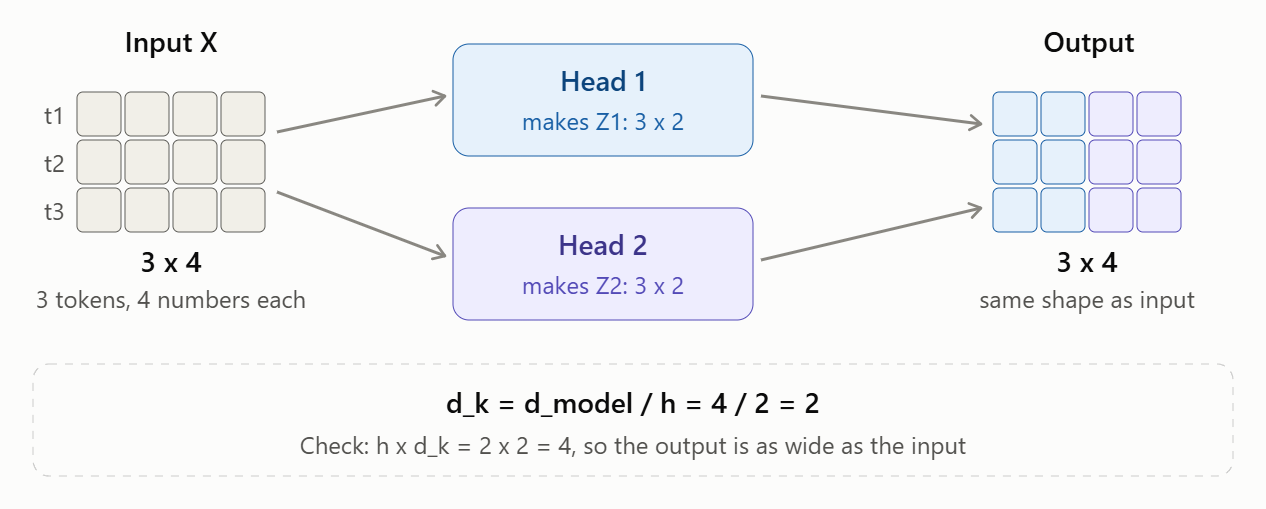

# Learned weights (hand-picked here)
## In real training these are learned by gradient descent. One (W_Q, W_K, W_V) per head. Where Are the Three $4 \times 2$ Weight Tables?

```py
W_Q = [np.array([[1, 0], [0, 1], [1, 0], [0, 1]], float),
       np.array([[0, 1], [1, 0], [0, 1], [1, 0]], float)]
W_K = [np.array([[1, 0], [0, 1], [1, 0], [1, 1]], float),
       np.array([[1, 1], [0, 1], [1, 0], [0, 1]], float)]
W_V = [np.array([[1, 0], [0, 1], [1, 1], [0, 0]], float),
       np.array([[0, 1], [1, 0], [0, 0], [1, 1]], float)]


```

## Big Picture
They were not shown in the widget. Only the results ($Q, K, V$) were drawn, and the weight tables are inside the Python file `mha_cookbook.py`, under the comment `"learned weights (hand-picked here)"`. Here they are.

## Summary
* Each head has three tables: $W_Q$, $W_K$, and $W_V$.
* Each table has **4 rows** (one per input number) and **2 columns** (one per output number).
* **Weight count:** Head 1 has $3 \times 8 = 24$ weights, Head 2 has $24$, and $W_O$ adds $16$. The total is **$64$**, matching $4 \times d_{\text{model}}^2$.
* These values were typed by hand so the arithmetic is easy to follow. In a real model, they are learned during training.

## Head 1 Tables
Each cell is the pair of numbers in that row of the table.

| Row *(input number)* | $W_Q$ | $W_K$ | $W_V$ |
| :--- | :--- | :--- | :--- |
| **1** | $[1, 0]$ | $[1, 0]$ | $[1, 0]$ |
| **2** | $[0, 1]$ | $[0, 1]$ | $[0, 1]$ |
| **3** | $[1, 0]$ | $[1, 0]$ | $[1, 1]$ |
| **4** | $[0, 1]$ | $[1, 1]$ | $[0, 0]$ |

## Head 2 Tables

| Row *(input number)* | $W_Q$ | $W_K$ | $W_V$ |
| :--- | :--- | :--- | :--- |
| **1** | $[0, 1]$ | $[1, 1]$ | $[0, 1]$ |
| **2** | $[1, 0]$ | $[0, 1]$ | $[1, 0]$ |
| **3** | $[0, 1]$ | $[1, 0]$ | $[0, 0]$ |
| **4** | $[1, 0]$ | $[0, 1]$ | $[1, 1]$ |

## Checking Your Screenshot with These Tables
Token $t_1$ is $x_1 = [1, 0, 1, 0]$. It has a $1$ in positions 1 and 3 and a $0$ elsewhere, so the multiplication simply adds rows 1 and 3 of each table:

| Result | $\text{Row } 1 + \text{Row } 3$ | Answer |
| :--- | :--- | :--- |
| **$q_1$** | $[1, 0] + [1, 0]$ | **$[2, 0]$** |
| **$k_1$** | $[1, 0] + [1, 0]$ | **$[2, 0]$** |
| **$v_1$** | $[1, 0] + [1, 1]$ | **$[2, 1]$** |

* These match the $t_1$ rows of the $Q, K,$ and $V$ grids in your screenshot.
* The shortcut works only because $X$ contains $0$s and $1$s. With real values such as $0.37$, you multiply each row by its number first and then add.

## How to Read a $4 \times 2$ Table
* **Rows:** One per input number, so 4 rows because $d_{\text{model}} = 4$.
* **Columns:** One per output number, so 2 columns because $d_k = 2$.
* **Dot product:** Each output number is a dot product of the token row with one column of the table.
* **Matrix dimensions:** A $(3 \times 4)$ times a $(4 \times 2)$ gives a $(3 \times 2)$. The inner size $4$ must match, and it disappears.


In [10]:
from IPython.display import IFrame

# Replace 'attention.html' with your actual file name
IFrame(src='./qkv_vectors_all_tokens_numeric.html', width='100%', height=680)

In [4]:
from IPython.display import IFrame

# Replace 'attention.html' with your actual file name
IFrame(src='./multi_head_attention_step_by_step.html', width='100%', height=600)


In [12]:
import numpy as np
W_Q = [np.array([[1, 0], [0, 1], [1, 0], [0, 1]], float),
       np.array([[0, 1], [1, 0], [0, 1], [1, 0]], float)]
X = np.array([[1, 0, 1, 0],
              [0, 1, 0, 1],
              [1, 1, 0, 0]], dtype=float)

print("X[0]:",X[0],"\nW_Q[0]: ",W_Q[0])
print("Dot Product X[0].W_Q[0] ==>", X[0] @ W_Q[0])

X[0]: [1. 0. 1. 0.] 
W_Q[0]:  [[1. 0.]
 [0. 1.]
 [1. 0.]
 [0. 1.]]
Dot Product X[0].W_Q[0] ==> [2. 0.]


In [2]:
"""
Multi-Head Attention Cookbook (NumPy only)
==========================================
Tiny example: n = 3 tokens, d_model = 4, h = 2 heads, so d_k = d_model / h = 2.
Because d_k = 2, every Q and K vector can be drawn as an arrow on a 2-D page.

Run:  python mha_cookbook.py
Reference: Vaswani et al., 2017, https://arxiv.org/abs/1706.03762
"""
import numpy as np

np.set_printoptions(precision=3, suppress=True)


def softmax(z):
    """Row-wise softmax. Subtracting the row max avoids overflow (numerical stability)."""
    e = np.exp(z - z.max(axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


def show(title, arr):
    print(f"\n{title}  shape={arr.shape}\n{arr}")


# ---------------------------------------------------------------- STEP 0: input
# 3 tokens (think: 3 one-minute bars), each described by 4 features.
X = np.array([[1, 0, 1, 0],
              [0, 1, 0, 1],
              [1, 1, 0, 0]], dtype=float)
n, d_model = X.shape
h = 2
d_k = d_model // h
show("STEP 0  X (n x d_model)", X)

# ------------------------------------------- learned weights (hand-picked here)
# In real training these are learned by gradient descent. One (W_Q, W_K, W_V) per head.
W_Q = [np.array([[1, 0], [0, 1], [1, 0], [0, 1]], float),
       np.array([[0, 1], [1, 0], [0, 1], [1, 0]], float)]
W_K = [np.array([[1, 0], [0, 1], [1, 0], [1, 1]], float),
       np.array([[1, 1], [0, 1], [1, 0], [0, 1]], float)]
W_V = [np.array([[1, 0], [0, 1], [1, 1], [0, 0]], float),
       np.array([[0, 1], [1, 0], [0, 0], [1, 1]], float)]
W_O = np.array([[1, 0, 0, 1],
                [0, 1, 1, 0],
                [1, 0, 1, 0],
                [0, 1, 0, 1]], float)          # (h*d_k) x d_model, mixes the heads


def one_head(X, Wq, Wk, Wv, d_k, name, causal=False, verbose=True):
    """Scaled dot-product attention for ONE head."""
    Q, K, V = X @ Wq, X @ Wk, X @ Wv                      # STEP 1: project
    S = Q @ K.T                                            # STEP 2: raw scores (dot products)
    S_scaled = S / np.sqrt(d_k)                            # STEP 3: scale by sqrt(d_k)
    if causal:                                             # optional: block the future
        S_scaled = np.where(np.triu(np.ones_like(S_scaled), k=1) == 1, -1e9, S_scaled)
    A = softmax(S_scaled)                                  # STEP 4: weights, each row sums to 1
    Z = A @ V                                              # STEP 5: weighted average of values
    if verbose:
        print(f"\n================ {name} ================")
        show("STEP 1  Q = X.W_Q", Q)
        show("STEP 1  K = X.W_K", K)
        show("STEP 1  V = X.W_V", V)
        show("STEP 2  S = Q.K^T (raw scores)", S)
        show(f"STEP 3  S / sqrt(d_k), sqrt({d_k}) = {np.sqrt(d_k):.3f}", S_scaled)
        show("STEP 4  A = softmax(S_scaled)  (rows sum to 1)", A)
        show("STEP 5  Z = A.V", Z)
    return Z, A


# ----------------------------------------------------- run each head in parallel
Z_heads, A_heads = [], []
for i in range(h):
    Z, A = one_head(X, W_Q[i], W_K[i], W_V[i], d_k, f"HEAD {i + 1}")
    Z_heads.append(Z)
    A_heads.append(A)

# ------------------------------------------------- STEP 6: concatenate the heads
C = np.concatenate(Z_heads, axis=1)                        # n x (h*d_k) = 3 x 4
show("STEP 6  Concat(Z1, Z2)", C)

# ------------------------------------------------------- STEP 7: output mixing
OUT = C @ W_O                                              # n x d_model
show("STEP 7  OUT = Concat . W_O", OUT)

# -------------------------------------------------------------------- sanity checks
assert np.allclose(A_heads[0].sum(axis=1), 1) and np.allclose(A_heads[1].sum(axis=1), 1)
assert OUT.shape == X.shape
print("\nChecks passed: each attention row sums to 1, output shape equals input shape.")

# ------------------------------------------------- BONUS A: causal mask unit test
# Rule: changing a FUTURE token must not change an earlier token's output.
X2 = X.copy()
X2[2] = [5, 5, 5, 5]                                       # alter the last token only
z_a, _ = one_head(X, W_Q[0], W_K[0], W_V[0], d_k, "", causal=True, verbose=False)
z_b, _ = one_head(X2, W_Q[0], W_K[0], W_V[0], d_k, "", causal=True, verbose=False)
assert np.allclose(z_a[:2], z_b[:2]), "Look-ahead leak!"
print("Causal-mask test passed: tokens 1-2 unchanged when token 3 changes.")

# ------------------------- BONUS B: full-size shape check (one NSE session of bars)
rng = np.random.default_rng(0)
n_big, dm, hh = 375, 512, 8
dk_big = dm // hh
Xb = rng.standard_normal((n_big, dm))
heads = []
for _ in range(hh):
    Wq, Wk, Wv = (rng.standard_normal((dm, dk_big)) * 0.05 for _ in range(3))
    z, _ = one_head(Xb, Wq, Wk, Wv, dk_big, "", causal=True, verbose=False)
    heads.append(z)
out_big = np.concatenate(heads, axis=1) @ (rng.standard_normal((dm, dm)) * 0.05)
print(f"\nFull-size run: input {Xb.shape} -> output {out_big.shape}; "
      f"per-head scores {n_big}x{n_big} = {n_big**2:,} pairs")



STEP 0  X (n x d_model)  shape=(3, 4)
[[1. 0. 1. 0.]
 [0. 1. 0. 1.]
 [1. 1. 0. 0.]]

================ HEAD 1 ================

STEP 1  Q = X.W_Q  shape=(3, 2)
[[2. 0.]
 [0. 2.]
 [1. 1.]]

STEP 1  K = X.W_K  shape=(3, 2)
[[2. 0.]
 [1. 2.]
 [1. 1.]]

STEP 1  V = X.W_V  shape=(3, 2)
[[2. 1.]
 [0. 1.]
 [1. 1.]]

STEP 2  S = Q.K^T (raw scores)  shape=(3, 3)
[[4. 2. 2.]
 [0. 4. 2.]
 [2. 3. 2.]]

STEP 3  S / sqrt(d_k), sqrt(2) = 1.414  shape=(3, 3)
[[2.828 1.414 1.414]
 [0.    2.828 1.414]
 [1.414 2.121 1.414]]

STEP 4  A = softmax(S_scaled)  (rows sum to 1)  shape=(3, 3)
[[0.673 0.164 0.164]
 [0.045 0.768 0.187]
 [0.248 0.503 0.248]]

STEP 5  Z = A.V  shape=(3, 2)
[[1.509 1.   ]
 [0.277 1.   ]
 [0.745 1.   ]]

================ HEAD 2 ================

STEP 1  Q = X.W_Q  shape=(3, 2)
[[0. 2.]
 [2. 0.]
 [1. 1.]]

STEP 1  K = X.W_K  shape=(3, 2)
[[2. 1.]
 [0. 2.]
 [1. 2.]]

STEP 1  V = X.W_V  shape=(3, 2)
[[0. 1.]
 [2. 1.]
 [1. 1.]]

STEP 2  S = Q.K^T (raw scores)  shape=(3, 3)
[[2. 4. 4.]
 [4